# Notebook 03: Text Preprocessing and TF-IDF Analysis

## Objectives

1. Load and validate the final PubMed corpus.
2. Preserve the original abstracts.
3. Apply conservative text preprocessing.
4. Prepare text for conventional NLP analysis.
5. Calculate TF-IDF scores for unigrams and bigrams.
6. Compare important terms and phrases across the three analytical layers.
7. Export the results for interpretation and inclusion in the thesis.

## Dataset

The dataset contains PubMed records classified into three
author-defined analytical layers:

- L1: Scientific Engagement
- L2: Safety and Risk
- L3: Comparative and Critical

The records contain publication metadata and biomedical abstracts.
They are not direct transcripts of Medical Science Liaison interactions.

In [2]:
# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import re
import html
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer

from IPython.display import display

print("Libraries imported successfully.")

Libraries imported successfully.


In [3]:
# ============================================================
# 2. LOAD DATASET
# ============================================================

DATASET_PATH = Path(
    "pubmed_medical_affairs_3layer_corpus_FINAL.csv"
)

if not DATASET_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATASET_PATH.resolve()}\n"
        "Place the CSV in the notebook's working directory "
        "or update DATASET_PATH."
    )

df = pd.read_csv(DATASET_PATH)

required_columns = [
    "pmid",
    "title",
    "abstract",
    "year",
    "journal",
    "layer",
]

missing_columns = [
    column for column in required_columns
    if column not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Required columns are missing: {missing_columns}"
    )

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)

print("\nRecords by layer:")
print(df["layer"].value_counts())

display(df.head(3))

Dataset loaded successfully.
Dataset shape: (21256, 6)

Records by layer:
layer
L1_scientific_engagement    9599
L3_comparative_critical     5849
L2_safety_risk              5808
Name: count, dtype: int64


,pmid,title,abstract,year,journal,layer
0,41483736,Intracranial activity of antibody-drug conjuga...,Antibody-drug conjugates (ADCs) represent a ra...,2025.0,Cancer treatment reviews,L1_scientific_engagement
1,41483728,Effect of quetiapine versus haloperidol on del...,INTRODUCTION: Delirium is a neuropsychiatric c...,2025.0,Asian journal of psychiatry,L1_scientific_engagement
2,41483727,Vision-language models in diagnostic imaging: ...,BACKGROUND: Radiology faces an unprecedented w...,2025.0,International journal of medical informatics,L1_scientific_engagement


In [4]:
# ============================================================
# 3. CONSERVATIVE TEXT PREPROCESSING
# ============================================================

# Work on a copy
df = df.copy()

# Preserve source text
df["abstract_original"] = (
    df["abstract"]
    .fillna("")
    .astype(str)
    .str.strip()
)

def clean_abstract(text):
    """
    Perform conservative text cleaning.

    The original abstract is preserved separately.
    """

    text = html.unescape(str(text))

    # Remove HTML tags
    text = re.sub(r"<[^>]+>", " ", text)

    # Standardise case
    text = text.lower()

    # Standardise whitespace
    text = re.sub(r"\s+", " ", text).strip()

    return text


df["abstract_clean"] = (
    df["abstract_original"].apply(clean_abstract)
)

# Calculate text length for reporting
df["abstract_word_count"] = (
    df["abstract_clean"].str.split().str.len()
)

print("Original records:", len(df))
print(
    "Records with empty cleaned abstracts:",
    df["abstract_clean"].eq("").sum()
)

print("\nOriginal abstract:")
print(df["abstract_original"].iloc[0][:500])

print("\nCleaned abstract:")
print(df["abstract_clean"].iloc[0][:500])

Original records: 21256
Records with empty cleaned abstracts: 0

Original abstract:
Antibody-drug conjugates (ADCs) represent a rapidly evolving class of therapeutics in non-small cell lung cancer (NSCLC), offering targeted delivery of cytotoxic payloads to tumor cells while minimizing off-target toxicity. Although ADCs have demonstrated promising results in NSCLC, their efficacy in treating central nervous system (CNS) metastases has been uncertain due to concerns over blood-brain barrier (BBB) penetration and the lack of dedicated CNS-specific evaluations in clinical trials. 

Cleaned abstract:
antibody-drug conjugates (adcs) represent a rapidly evolving class of therapeutics in non-small cell lung cancer (nsclc), offering targeted delivery of cytotoxic payloads to tumor cells while minimizing off-target toxicity. although adcs have demonstrated promising results in nsclc, their efficacy in treating central nervous system (cns) metastases has been uncertain due to concerns over blood

In [5]:
# ============================================================
# 4. PREPARE TEXT FOR TF-IDF
# ============================================================

analysis_df = df.loc[
    df["abstract_clean"].str.strip().ne("")
    & df["layer"].notna()
].copy()

print("Records included in TF-IDF:", len(analysis_df))

print("\nLayer counts:")
print(analysis_df["layer"].value_counts())

print("\nWord-count summary:")
display(
    analysis_df.groupby("layer")["abstract_word_count"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
)

Records included in TF-IDF: 21256

Layer counts:
layer
L1_scientific_engagement    9599
L3_comparative_critical     5849
L2_safety_risk              5808
Name: count, dtype: int64

Word-count summary:


,count,mean,median,min,max
layer,,,,,
L1_scientific_engagement,9599,232.81,227.0,43,2178
L2_safety_risk,5808,239.23,229.0,40,1033
L3_comparative_critical,5849,219.60,210.0,1,991


In [6]:
# ============================================================
# 5. TF-IDF ANALYSIS: UNIGRAMS AND BIGRAMS
# ============================================================

def extract_top_tfidf_terms(
    texts,
    top_n=20,
    ngram_range=(1, 1)
):
    """
    Calculate average TF-IDF scores and return the
    highest-scoring terms or phrases.
    """

    vectorizer = TfidfVectorizer(
        stop_words="english",
        ngram_range=ngram_range,
        min_df=5,
        max_df=0.90,
        max_features=30000,
        sublinear_tf=True,
        dtype=np.float32
    )

    matrix = vectorizer.fit_transform(texts)

    terms = vectorizer.get_feature_names_out()

    mean_scores = np.asarray(
        matrix.mean(axis=0)
    ).ravel()

    results = pd.DataFrame({
        "term": terms,
        "mean_tfidf": mean_scores
    })

    return (
        results.sort_values(
            "mean_tfidf",
            ascending=False
        )
        .head(top_n)
        .reset_index(drop=True)
    )


# ------------------------------------------------------------
# 1. TF-IDF UNIGRAMS: INDIVIDUAL WORDS
# ------------------------------------------------------------

top_unigrams = {}

for layer_name in sorted(analysis_df["layer"].unique()):

    texts = analysis_df.loc[
        analysis_df["layer"] == layer_name,
        "abstract_clean"
    ].tolist()

    results = extract_top_tfidf_terms(
        texts,
        top_n=20,
        ngram_range=(1, 1)
    )

    top_unigrams[layer_name] = results

    print(f"\nTOP UNIGRAMS — {layer_name}")
    display(results)


# ------------------------------------------------------------
# 2. TF-IDF BIGRAMS: TWO-WORD PHRASES
# ------------------------------------------------------------

top_bigrams = {}

for layer_name in sorted(analysis_df["layer"].unique()):

    texts = analysis_df.loc[
        analysis_df["layer"] == layer_name,
        "abstract_clean"
    ].tolist()

    results = extract_top_tfidf_terms(
        texts,
        top_n=20,
        ngram_range=(2, 2)
    )

    top_bigrams[layer_name] = results

    print(f"\nTOP BIGRAMS — {layer_name}")
    display(results)


# ------------------------------------------------------------
# 3. COMBINE AND EXPORT RESULTS
# ------------------------------------------------------------

unigram_export = []

for layer_name, results in top_unigrams.items():

    temp = results.copy()
    temp["layer"] = layer_name
    unigram_export.append(temp)

unigram_export = pd.concat(
    unigram_export,
    ignore_index=True
)

bigram_export = []

for layer_name, results in top_bigrams.items():

    temp = results.copy()
    temp["layer"] = layer_name
    bigram_export.append(temp)

bigram_export = pd.concat(
    bigram_export,
    ignore_index=True
)

unigram_export.to_csv(
    "tfidf_top_unigrams_by_layer.csv",
    index=False
)

bigram_export.to_csv(
    "tfidf_top_bigrams_by_layer.csv",
    index=False
)

print("\nTF-IDF analysis completed successfully.")
print("Unigram results:", unigram_export.shape)
print("Bigram results:", bigram_export.shape)


TOP UNIGRAMS — L1_scientific_engagement


,term,mean_tfidf
0,clinical,0.023259
1,patients,0.022317
2,treatment,0.021988
3,review,0.020410
4,studies,0.020303
5,efficacy,0.020263
6,therapeutic,0.018178
7,cancer,0.017455
8,outcomes,0.016800
9,potential,0.016070



TOP UNIGRAMS — L2_safety_risk


,term,mean_tfidf
0,patients,0.023282
1,clinical,0.021860
2,review,0.020840
3,studies,0.020259
4,safety,0.020252
5,treatment,0.020076
6,outcomes,0.017111
7,risk,0.016213
8,including,0.016010
9,potential,0.015272



TOP UNIGRAMS — L3_comparative_critical


...


TOP BIGRAMS — L2_safety_risk


,term,mean_tfidf
0,95 ci,0.014366
1,adverse events,0.013770
2,long term,0.011142
3,systematic review,0.008143
4,meta analysis,0.007477
5,clinical trials,0.007382
6,quality life,0.006682
7,randomized controlled,0.006068
8,controlled trials,0.005937
9,web science,0.005843



TOP BIGRAMS — L3_comparative_critical


,term,mean_tfidf
0,95 ci,0.010133
1,long term,0.009334
2,artificial intelligence,0.008216
3,systematic review,0.008152
4,future research,0.007617
5,meta analysis,0.006656
6,public health,0.006304
7,web science,0.006229
8,quality life,0.006086
9,recent advances,0.005907



TF-IDF analysis completed successfully.
Unigram results: (60, 3)
Bigram results: (60, 3)


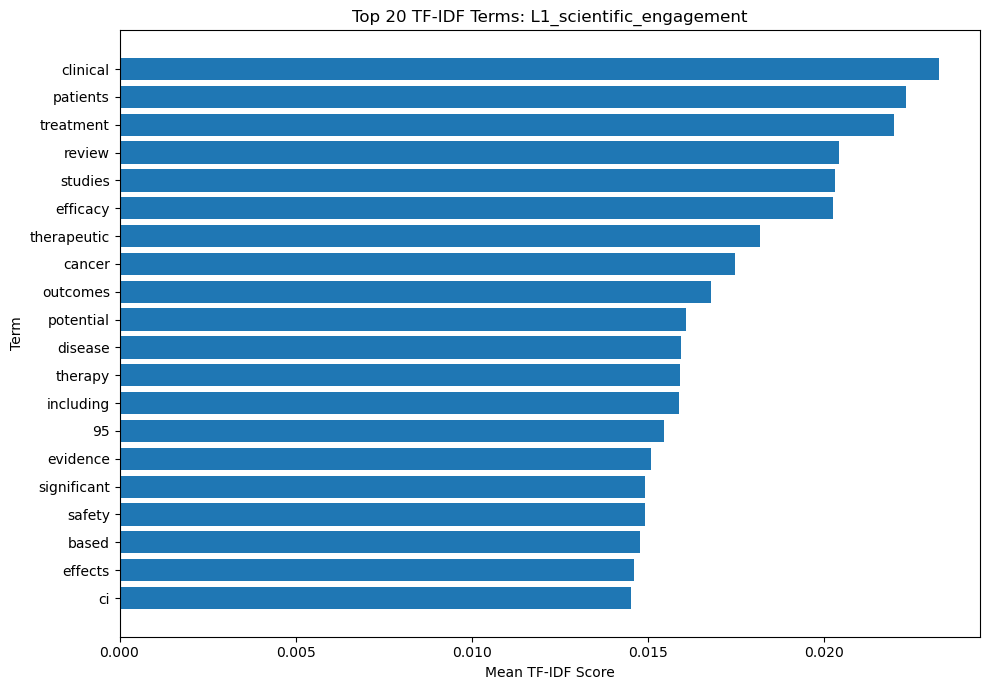

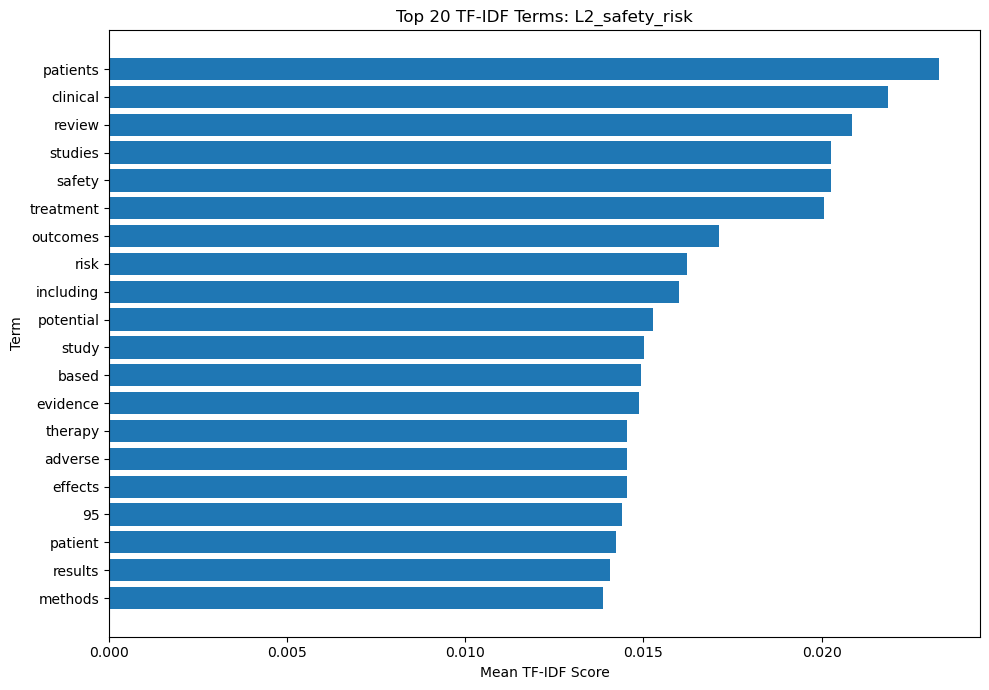

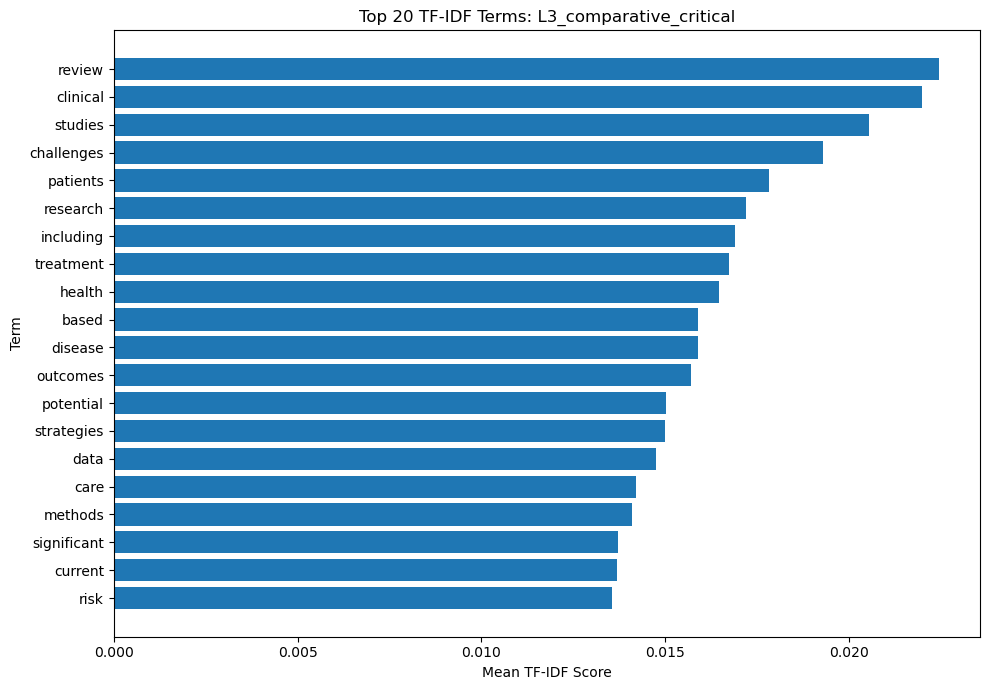

TF-IDF visualisations saved.


In [7]:
# ============================================================
# 6. VISUALISE TOP TF-IDF TERMS BY LAYER
# ============================================================

for layer_name, results in top_unigrams.items():

    plot_data = results.sort_values(
        "mean_tfidf",
        ascending=True
    )

    plt.figure(figsize=(10, 7))

    plt.barh(
        plot_data["term"],
        plot_data["mean_tfidf"]
    )

    plt.xlabel("Mean TF-IDF Score")
    plt.ylabel("Term")
    plt.title(f"Top 20 TF-IDF Terms: {layer_name}")

    plt.tight_layout()
    plt.savefig(
        f"tfidf_top_terms_{layer_name}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

print("TF-IDF visualisations saved.")